## **Data Ingestion**

In [0]:
import pandas as pd
import numpy as np

In [0]:
patients = spark.table("analystlab.default.patients").toPandas()

display(patients)

Id,BIRTHDATE,DEATHDATE,PREFIX,FIRST,LAST,SUFFIX,MAIDEN,MARITAL,RACE,ETHNICITY,GENDER,BIRTHPLACE,ADDRESS,CITY,STATE,COUNTY,ZIP,LAT,LON
5605b66b-e92d-c16c-1b83-b8bf7040d51f,1977-03-19,null,Mrs.,Nikita578,Erdman779,null,Leannon79,M,white,nonhispanic,F,Wakefield Massachusetts US,510 Little Station Unit 69,Quincy,Massachusetts,Norfolk County,2186.0,42.290937381211286,-70.97550306
6e5ae27c-8038-7988-e2c0-25a103f01bfa,1940-02-19,null,Mr.,Zane918,Hodkiewicz467,null,null,M,white,nonhispanic,M,Brookline Massachusetts US,747 Conn Throughway,Boston,Massachusetts,Suffolk County,2135.0,42.308831197562505,-71.0631616
8123d076-0886-9007-e956-d5864aa121a7,1958-06-04,null,Mr.,Quinn173,Marquardt819,null,null,M,white,nonhispanic,M,Gardner Massachusetts US,816 Okuneva Extension Apt 91,Quincy,Massachusetts,Norfolk County,2170.0,42.26517684888508,-70.96708508
770518e4-6133-648e-60c9-071eb2f0e2ce,1928-12-25,2017-09-29,Mr.,Abel832,Smitham825,null,null,M,white,hispanic,M,Randolph Massachusetts US,127 Cole Way Unit 95,Boston,Massachusetts,Suffolk County,2118.0,42.334303740740594,-71.0668012
f96addf5-81b9-0aab-7855-d208d3d352c5,1928-12-25,2014-02-23,Mr.,Edwin773,Labadie908,null,null,M,white,hispanic,M,Stow Massachusetts US,976 Ziemann Gateway,Boston,Massachusetts,Suffolk County,2125.0,42.346771403899275,-71.05881297
8e9650d1-788a-78f9-4a28-d08f7f95354a,1928-12-25,null,Mr.,Frankie174,Oberbrunner298,null,null,M,white,hispanic,M,Boston Massachusetts US,303 Bechtelar Bypass Suite 26,Boston,Massachusetts,Suffolk County,2467.0,42.37102647,-71.11810672
183df435-4190-060e-8f8e-bf63c572b266,1957-11-08,null,Mrs.,Eilene124,Walsh511,null,Wiegand701,M,asian,nonhispanic,F,Beijing Beijing Municipality CN,235 Lang Parade,Cambridge,Massachusetts,Middlesex County,2142.0,42.35892760552785,-71.15622361
720560d4-51da-c38c-ee90-c15935278df1,1972-06-27,null,Mr.,Lowell343,Price929,null,null,M,white,nonhispanic,M,Lowell Massachusetts US,694 Kuhlman Corner Apt 74,Quincy,Massachusetts,Norfolk County,2170.0,42.297903944576696,-71.01598304
217851b0-5f47-d376-18b9-0fe4ba77207e,1954-03-06,null,Mr.,Adrian111,Gleason633,null,null,S,black,hispanic,M,Boston Massachusetts US,808 Gottlieb Wall,Boston,Massachusetts,Suffolk County,2126.0,42.38408414202098,-71.1006892
ff331e5c-ab16-e218-f39a-63e11de1ed75,1927-07-10,null,Mr.,Eugene421,Abernathy524,null,null,M,native,hispanic,M,Pembroke Massachusetts US,706 Connelly Track Unit 1,Boston,Massachusetts,Suffolk County,2111.0,42.358519313454885,-71.07859759


In [0]:
# Check the number of rows and columns
print("Dataset shape:", patients.shape)

Dataset shape: (974, 20)


In [0]:
# Display column names
print("\nColumn names:")
print(patients.columns.tolist())


Column names:
['Id', 'BIRTHDATE', 'DEATHDATE', 'PREFIX', 'FIRST', 'LAST', 'SUFFIX', 'MAIDEN', 'MARITAL', 'RACE', 'ETHNICITY', 'GENDER', 'BIRTHPLACE', 'ADDRESS', 'CITY', 'STATE', 'COUNTY', 'ZIP', 'LAT', 'LON']


In [0]:
 # Check data types
print("\nData types:")
print(patients.dtypes)


Data types:
Id             object
BIRTHDATE      object
DEATHDATE      object
PREFIX         object
FIRST          object
LAST           object
SUFFIX         object
MAIDEN         object
MARITAL        object
RACE           object
ETHNICITY      object
GENDER         object
BIRTHPLACE     object
ADDRESS        object
CITY           object
STATE          object
COUNTY         object
ZIP           float64
LAT           float64
LON           float64
dtype: object


In [0]:
# Check missing values
print("\nMissing values:")
print(patients.isnull().sum())


Missing values:
Id              0
BIRTHDATE       0
DEATHDATE     820
PREFIX          0
FIRST           0
LAST            0
SUFFIX        953
MAIDEN        588
MARITAL         1
RACE            0
ETHNICITY       0
GENDER          0
BIRTHPLACE      0
ADDRESS         0
CITY            0
STATE           0
COUNTY          0
ZIP           142
LAT             0
LON             0
dtype: int64


In [0]:
# Check exact duplicate records
print("\nDuplicate records:", patients.duplicated().sum())


Duplicate records: 0


In [0]:
 
# Count missing values in each column
print(patients.isnull().sum())


Id              0
BIRTHDATE       0
DEATHDATE     820
PREFIX          0
FIRST           0
LAST            0
SUFFIX        953
MAIDEN        588
MARITAL         1
RACE            0
ETHNICITY       0
GENDER          0
BIRTHPLACE      0
ADDRESS         0
CITY            0
STATE           0
COUNTY          0
ZIP           142
LAT             0
LON             0
dtype: int64


## **Conduct Exploratory Data Analysis (EDA)**

In [0]:
 
# Step 1: Identify all text columns
text_columns = [
    column
    for column in patients.select_dtypes(
        include=["object", "string"]
    ).columns
    if pd.api.types.infer_dtype(patients[column], skipna=True) == "string"
]

# Step 2: Remove unnecessary spaces
for column in text_columns:
    patients[column] = patients[column].str.strip()

# Step 3: Standardise gender values
patients["GENDER"] = patients["GENDER"].str.upper()

# Step 4: Standardise ethnicity values
patients["ETHNICITY"] = (
    patients["ETHNICITY"].str.lower()
)

# Step 5: Standardise geographical text
patients["CITY"] = patients["CITY"].str.title()
patients["STATE"] = patients["STATE"].str.title()
patients["COUNTY"] = patients["COUNTY"].str.title()

# Step 6: Display the first five cleaned records
patients.head()


,Id,BIRTHDATE,DEATHDATE,PREFIX,FIRST,LAST,SUFFIX,MAIDEN,MARITAL,RACE,ETHNICITY,GENDER,BIRTHPLACE,ADDRESS,CITY,STATE,COUNTY,ZIP,LAT,LON
0,5605b66b-e92d-c16c-1b83-b8bf7040d51f,1977-03-19,None,Mrs.,Nikita578,Erdman779,None,Leannon79,M,white,nonhispanic,F,Wakefield Massachusetts US,510 Little Station Unit 69,Quincy,Massachusetts,Norfolk County,2186.0,42.290937,-70.975503
1,6e5ae27c-8038-7988-e2c0-25a103f01bfa,1940-02-19,None,Mr.,Zane918,Hodkiewicz467,None,None,M,white,nonhispanic,M,Brookline Massachusetts US,747 Conn Throughway,Boston,Massachusetts,Suffolk County,2135.0,42.308831,-71.063162
2,8123d076-0886-9007-e956-d5864aa121a7,1958-06-04,None,Mr.,Quinn173,Marquardt819,None,None,M,white,nonhispanic,M,Gardner Massachusetts US,816 Okuneva Extension Apt 91,Quincy,Massachusetts,Norfolk County,2170.0,42.265177,-70.967085
3,770518e4-6133-648e-60c9-071eb2f0e2ce,1928-12-25,2017-09-29,Mr.,Abel832,Smitham825,None,None,M,white,hispanic,M,Randolph Massachusetts US,127 Cole Way Unit 95,Boston,Massachusetts,Suffolk County,2118.0,42.334304,-71.066801
4,f96addf5-81b9-0aab-7855-d208d3d352c5,1928-12-25,2014-02-23,Mr.,Edwin773,Labadie908,None,None,M,white,hispanic,M,Stow Massachusetts US,976 Ziemann Gateway,Boston,Massachusetts,Suffolk County,2125.0,42.346771,-71.058813


In [0]:
 
# Check missing values in each column
missing_values = patients.isnull().sum()

# Calculate the percentage of missing values
missing_percentage = (
    patients.isnull().sum() / len(patients)
) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage.round(2)
})


print(missing_summary)


            Missing Values  Missing Percentage
Id                       0                0.00
BIRTHDATE                0                0.00
DEATHDATE              820               84.19
PREFIX                   0                0.00
FIRST                    0                0.00
LAST                     0                0.00
SUFFIX                 953               97.84
MAIDEN                 588               60.37
MARITAL                  1                0.10
RACE                     0                0.00
ETHNICITY                0                0.00
GENDER                   0                0.00
BIRTHPLACE               0                0.00
ADDRESS                  0                0.00
CITY                     0                0.00
STATE                    0                0.00
COUNTY                   0                0.00
ZIP                    142               14.58
LAT                      0                0.00
LON                      0                0.00


In [0]:
 
# Check missing values in the "MARITAL" column
# Replace the missing marital status with "Unknown"
patients["MARITAL"] = patients["MARITAL"].fillna("Unknown")

# Check missing values again
print(patients["MARITAL"].isnull().sum())

# Display marital status categories
print(patients["MARITAL"].value_counts())


0
MARITAL
M          784
S          189
Unknown      1
Name: count, dtype: int64


In [0]:
 
# Count exact duplicate rows
duplicate_count = patients.duplicated().sum()

# Display the number of duplicates
print("Number of duplicate records:", duplicate_count)


Number of duplicate records: 0


In [0]:
 
# Check the number of unique patient IDs
unique_ids = patients["Id"].nunique()

# Count total patient records
total_records = len(patients)

# Count duplicate patient IDs
duplicate_ids = patients["Id"].duplicated().sum()

# Display results
print("Total patient records:", total_records)
print("Unique patient IDs:", unique_ids)
print("Duplicate patient IDs:", duplicate_ids)


Total patient records: 974
Unique patient IDs: 974
Duplicate patient IDs: 0


In [0]:
 # Display the data types of all columns
print(patients.dtypes)


Id             object
BIRTHDATE      object
DEATHDATE      object
PREFIX         object
FIRST          object
LAST           object
SUFFIX         object
MAIDEN         object
MARITAL        object
RACE           object
ETHNICITY      object
GENDER         object
BIRTHPLACE     object
ADDRESS        object
CITY           object
STATE          object
COUNTY         object
ZIP           float64
LAT           float64
LON           float64
dtype: object


In [0]:
 
# Convert BIRTHDATE into datetime format
patients["BIRTHDATE"] = pd.to_datetime(
    patients["BIRTHDATE"],
    errors="coerce"
)

# Convert DEATHDATE into datetime format
patients["DEATHDATE"] = pd.to_datetime(
    patients["DEATHDATE"],
    errors="coerce"
)

# Check the updated data types
print(patients[["BIRTHDATE", "DEATHDATE"]].dtypes)


BIRTHDATE    datetime64[ns]
DEATHDATE    datetime64[ns]
dtype: object


In [0]:
 
# Check ZIP, LAT and LON
# Convert ZIP into string format
patients["ZIP"] = (
    patients["ZIP"].astype("Int64").astype("string")
)

# Check the data types
print(patients[["ZIP", "LAT", "LON"]].dtypes)

# Display the first five records
print(patients[["ZIP", "LAT", "LON"]].head())


ZIP    string[python]
LAT           float64
LON           float64
dtype: object
    ZIP        LAT        LON
0  2186  42.290937 -70.975503
1  2135  42.308831 -71.063162
2  2170  42.265177 -70.967085
3  2118  42.334304 -71.066801
4  2125  42.346771 -71.058813


In [0]:
 
# Check the final dataset dimensions
print("Dataset shape:", patients.shape)

# Check missing values
print("\nMissing values:")
print(patients.isnull().sum())

# Check duplicate records
print("\nDuplicate records:", patients.duplicated().sum())

# Check duplicate patient IDs
print("Duplicate patient IDs:", patients["Id"].duplicated().sum())

# Check data types
print("\nData types:")
print(patients.dtypes)


Dataset shape: (974, 20)

Missing values:
Id              0
BIRTHDATE       0
DEATHDATE     820
PREFIX          0
FIRST           0
LAST            0
SUFFIX        953
MAIDEN        588
MARITAL         0
RACE            0
ETHNICITY       0
GENDER          0
BIRTHPLACE      0
ADDRESS         0
CITY            0
STATE           0
COUNTY          0
ZIP           142
LAT             0
LON             0
dtype: int64

Duplicate records: 0
Duplicate patient IDs: 0

Data types:
Id                    object
BIRTHDATE     datetime64[ns]
DEATHDATE     datetime64[ns]
PREFIX                object
FIRST                 object
LAST                  object
SUFFIX                object
MAIDEN                object
MARITAL               object
RACE                  object
ETHNICITY             object
GENDER                object
BIRTHPLACE            object
ADDRESS               object
CITY                  object
STATE                 object
COUNTY                object
ZIP           string[python]
LAT

In [0]:
 
# Count patients in each race category
race_counts = patients["RACE"].value_counts()

# Display race categories and their counts
print("Different Race Categories:")
print(race_counts)

# Count the number of unique race categories
print("\nNumber of unique race categories:")
print(patients["RACE"].nunique())


Different Race Categories:
RACE
white       680
black       163
asian        91
other        16
hawaiian     13
native       11
Name: count, dtype: int64

Number of unique race categories:
6


In [0]:
 
# Count unique birthplaces
unique_birthplaces = patients["BIRTHPLACE"].nunique()

print("Number of unique birthplaces:", unique_birthplaces)

# Display all unique birthplaces
print("\nUnique Birthplaces:")
print(sorted(patients["BIRTHPLACE"].dropna().unique()))


Number of unique birthplaces: 297

Unique Birthplaces:
['Abington  Massachusetts  US', 'Acton  Massachusetts  US', 'Acushnet  Massachusetts  US', 'Adams  Massachusetts  US', 'Agawam  Massachusetts  US', 'Ahmedabad  Gujarat  IN', 'Amesbury  Massachusetts  US', 'Amherst  Massachusetts  US', 'Amherst Center  Massachusetts  US', 'Andover  Massachusetts  US', 'Arlington  Massachusetts  US', 'Ashburnham  Massachusetts  US', 'Ashland  Massachusetts  US', 'Athens  Athens Prefecture  GR', 'Athol  Massachusetts  US', 'Attleboro  Massachusetts  US', 'Auburn  Massachusetts  US', 'Barnstable  Massachusetts  US', 'Bedford  Massachusetts  US', 'Beijing  Beijing Municipality  CN', 'Belchertown  Massachusetts  US', 'Bellingham  Massachusetts  US', 'Belmont  Massachusetts  US', 'Berlin  Berlin  DE', 'Berlin  Massachusetts  US', 'Beverly  Massachusetts  US', 'Billerica  Massachusetts  US', 'Bliss Corner  Massachusetts  US', 'Bogota  Bogota  CO', 'Boston  Massachusetts  US', 'Bourne  Massachusetts  US', '

In [0]:
 
# Count the 10 most common birthplaces
top_birthplaces = patients["BIRTHPLACE"].value_counts().head(10)

print("Top 10 Most Common Birthplaces:")
print(top_birthplaces)


Top 10 Most Common Birthplaces:
BIRTHPLACE
Boston  Massachusetts  US         79
Worcester  Massachusetts  US      20
Somerville  Massachusetts  US     17
Springfield  Massachusetts  US    17
Brockton  Massachusetts  US       14
Lowell  Massachusetts  US         14
Lynn  Massachusetts  US           13
Attleboro  Massachusetts  US      11
Cambridge  Massachusetts  US      11
Revere  Massachusetts  US         10
Name: count, dtype: int64


In [0]:
 
# Extract birth year
patients["BIRTH_YEAR"] = patients["BIRTHDATE"].dt.year

# Extract birth month
patients["BIRTH_MONTH"] = patients["BIRTHDATE"].dt.month

# Extract birth day
patients["BIRTH_DAY"] = patients["BIRTHDATE"].dt.day

# Display the extracted date components
print(patients[
    ["BIRTHDATE", "BIRTH_YEAR", "BIRTH_MONTH", "BIRTH_DAY"]
].head())


   BIRTHDATE  BIRTH_YEAR  BIRTH_MONTH  BIRTH_DAY
0 1977-03-19        1977            3         19
1 1940-02-19        1940            2         19
2 1958-06-04        1958            6          4
3 1928-12-25        1928           12         25
4 1928-12-25        1928           12         25


In [0]:
 
# Set the reference date
reference_date = pd.Timestamp("2026-11-23")

# Calculate age in completed years
patients["AGE"] = (
    reference_date.year - patients["BIRTHDATE"].dt.year
    - (
        (reference_date.month < patients["BIRTHDATE"].dt.month)
        | (
            (reference_date.month == patients["BIRTHDATE"].dt.month)
            & (reference_date.day < patients["BIRTHDATE"].dt.day)
        )
    ).astype(int)
)

# Display birthdate and calculated age
print(patients[["BIRTHDATE", "AGE"]].head(10))


   BIRTHDATE  AGE
0 1977-03-19   49
1 1940-02-19   86
2 1958-06-04   68
3 1928-12-25   97
4 1928-12-25   97
5 1928-12-25   97
6 1957-11-08   69
7 1972-06-27   54
8 1954-03-06   72
9 1927-07-10   99


In [0]:
 
# Display the original birthdate and extracted components
print(
    patients[
        ["BIRTHDATE", "BIRTH_YEAR", "BIRTH_MONTH", "BIRTH_DAY"]
    ].head(10)
)


   BIRTHDATE  BIRTH_YEAR  BIRTH_MONTH  BIRTH_DAY
0 1977-03-19        1977            3         19
1 1940-02-19        1940            2         19
2 1958-06-04        1958            6          4
3 1928-12-25        1928           12         25
4 1928-12-25        1928           12         25
5 1928-12-25        1928           12         25
6 1957-11-08        1957           11          8
7 1972-06-27        1972            6         27
8 1954-03-06        1954            3          6
9 1927-07-10        1927            7         10


In [0]:
# Calculate summary statistics for patient age
print(patients["AGE"].describe())

count    974.000000
mean      74.147844
std       20.496427
min       34.000000
25%       56.000000
50%       76.000000
75%       93.000000
max      104.000000
Name: AGE, dtype: float64


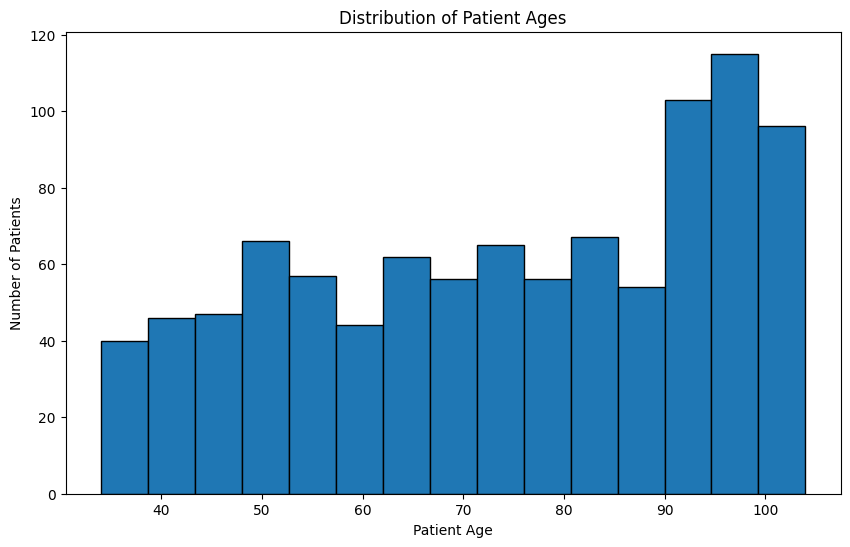

In [0]:
import matplotlib.pyplot as plt

# Create a histogram of patient ages
plt.figure(figsize=(10, 6))

plt.hist(patients["AGE"], bins=15, edgecolor="black")

# Add chart labels and title
plt.title("Distribution of Patient Ages")
plt.xlabel("Patient Age")
plt.ylabel("Number of Patients")

plt.show()

In [0]:
# Count patients in each marital status category
marital_counts = patients["MARITAL"].value_counts()

# Calculate percentages
marital_percentages = patients["MARITAL"].value_counts(normalize=True) * 100

# Combine counts and percentages into a table
marital_summary = pd.DataFrame({
    "Count": marital_counts,
    "Percentage": marital_percentages.round(2)
})

# Display the results
print(marital_summary)

         Count  Percentage
MARITAL                   
M          784       80.49
S          189       19.40
Unknown      1        0.10


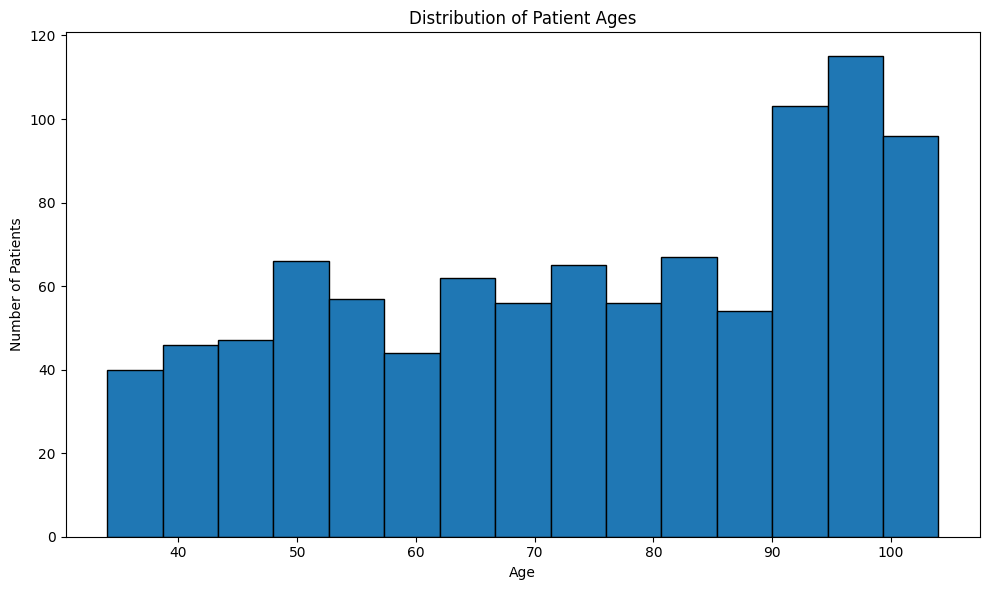

In [0]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(patients["AGE"], bins=15, edgecolor="black")

plt.title("Distribution of Patient Ages")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

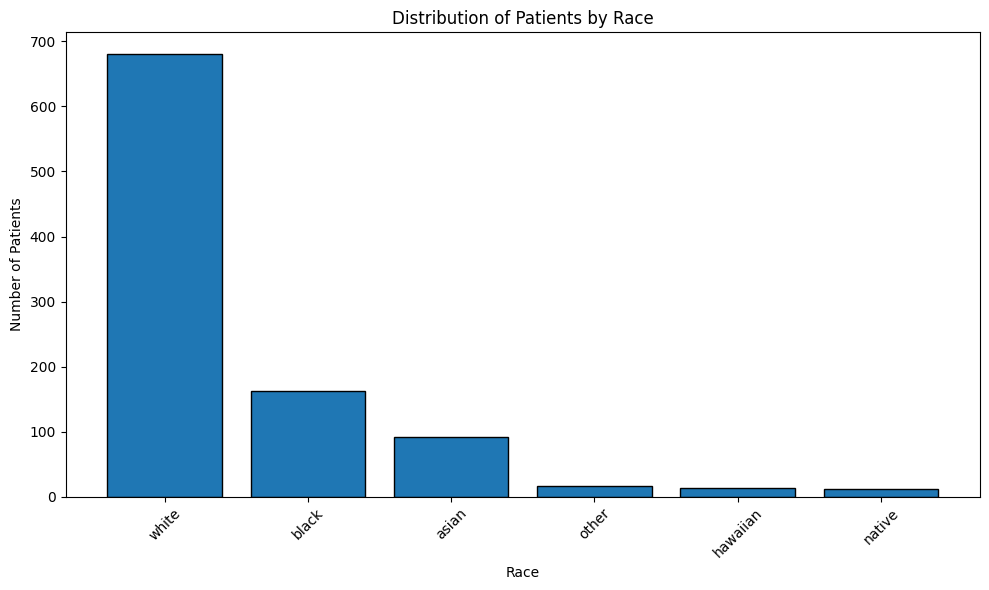

In [0]:
race_counts = patients["RACE"].value_counts()

plt.figure(figsize=(10, 6))

plt.bar(race_counts.index, race_counts.values, edgecolor="black")

plt.title("Distribution of Patients by Race")
plt.xlabel("Race")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

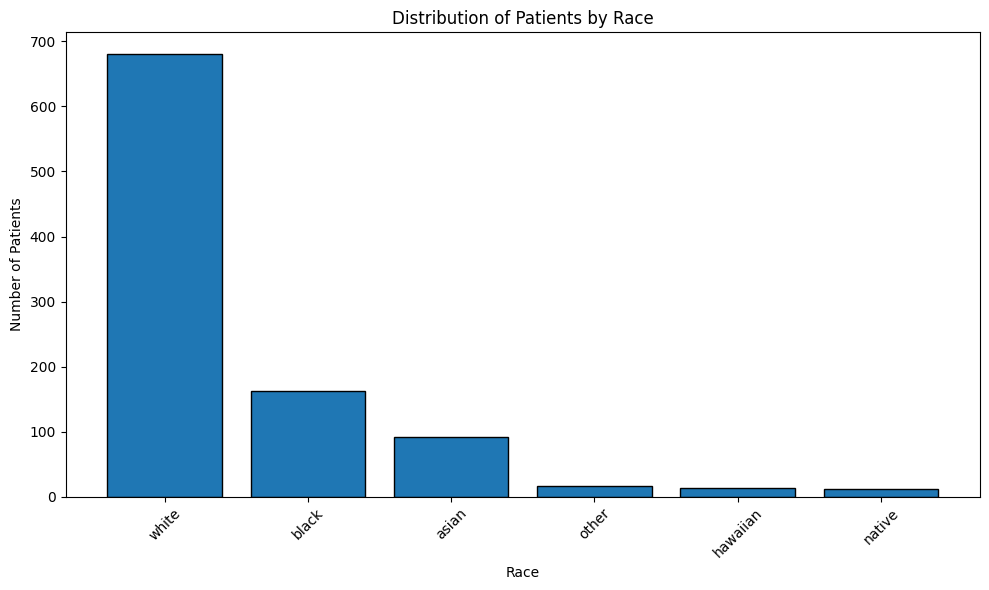

In [0]:
race_counts = patients["RACE"].value_counts()

plt.figure(figsize=(10, 6))

plt.bar(race_counts.index, race_counts.values, edgecolor="black")

plt.title("Distribution of Patients by Race")
plt.xlabel("Race")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Interpretation of Patient Dataset Results and Limitations

The exploratory data analysis of the patient dataset provided insights into the demographic characteristics of 974 patients. The age analysis showed an average patient age of approximately 74 years, with ages ranging from 34 to 104 years. The gender and race visualisations provided an overview of the demographic composition of the dataset. The race analysis showed that the White category accounted for the largest proportion of recorded patients (69.82%), followed by Black (16.74%) and Asian (9.34%).

However, these findings are descriptive and do not establish causal relationships or explain the reasons behind the observed demographic patterns. The patient dataset alone cannot determine whether age, gender or race influences hospital costs, treatment decisions, healthcare access or patient outcomes. It also cannot establish whether the sample represents the wider population. Further analysis using linked encounter, procedure and payer datasets is necessary to investigate hospital operations and the relationship between patient characteristics and healthcare costs.

**## Task 3: Form and test hypotheses**

In [0]:
 
from scipy.stats import ttest_ind

# Separate patient ages by gender
female_age = patients[patients["GENDER"] == "F"]["AGE"]
male_age = patients[patients["GENDER"] == "M"]["AGE"]

# Conduct an independent-samples t-test
t_stat, p_value = ttest_ind(
    female_age,
    male_age,
    equal_var=False
)

# Display the results
print("T-statistic:", t_stat)
print("P-value:", p_value)


T-statistic: -1.7187070455442033
P-value: 0.08598619213127665


**Assumption checking**

Before conducting Welch's independent-samples t-test, the age data were examined separately for female and male patients. The female group contained 480 patients, while the male group contained 494 patients. No missing age values were identified. The standard deviations were relatively similar, at 20.30 years for female patients and 20.64 years for male patients. Both groups had large sample sizes, making the test reasonably robust to moderate departures from normality. The dataset also contained 974 unique patient IDs, supporting the assumption that each patient was represented once. Welch's t-test was therefore considered an appropriate method for comparing the average ages of the two groups.

In [0]:
 
# Check descriptive statistics for each gender group
print(patients.groupby("GENDER")["AGE"].describe())

# Check for missing age values
print("\nMissing age values:")
print(patients["AGE"].isnull().sum())


        count       mean        std   min   25%   50%   75%    max
GENDER                                                            
F       480.0  73.004167  20.301382  34.0  55.0  74.0  93.0  104.0
M       494.0  75.259109  20.644034  35.0  59.0  78.0  94.0  104.0

Missing age values:
0


Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


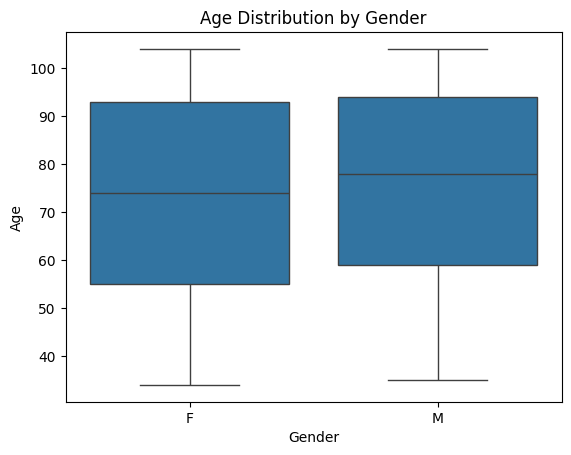

In [0]:
%pip install seaborn
 
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(data=patients, x="GENDER", y="AGE")

plt.title("Age Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Age")
plt.show()


### 5. Results and Interpretation

The analysis of the Patients dataset revealed several demographic patterns among the 974 recorded patients.

**Age findings**

The average patient age was approximately 74.15 years, while the median age was 76 years. Patient ages ranged from 34 to 104 years, indicating that the dataset mainly represented older individuals.

**Gender findings**

The dataset contained 480 female patients (49.28%) and 494 male patients (50.72%). The gender distribution was relatively balanced.

**Race and ethnicity findings**

White patients represented the largest racial group, accounting for 69.82% of the dataset, followed by Black patients at 16.74% and Asian patients at 9.34%. Non-Hispanic patients accounted for 783 records, while Hispanic patients accounted for 191 records.

**Statistical test results**

Welch's independent-samples t-test was conducted to determine whether average patient age differed between female and male patients. The test produced a t-statistic of -1.7187 and a p-value of 0.08599.

Since the p-value was greater than the 0.05 significance level, the null hypothesis was not rejected. Although male patients had a higher average age of 75.26 years compared with 73.00 years for female patients, the difference was not statistically significant.

**Overall interpretation**

The findings describe the demographic composition of the patients in the dataset. The statistical analysis did not provide sufficient evidence of a difference in average age between female and male patients. These results should be interpreted as descriptive findings about the available records rather than evidence of differences in health conditions, healthcare needs or clinical outcomes.

 Task 4: Investigate limitations
- Explain how missing values, unequal group sizes, repeated records, potential confounding factors, or limited data coverage could affect your conclusions.

In [0]:
#Unequal group sizes
# Count patients in each gender group
gender_counts = patients["GENDER"].value_counts()

# Calculate the percentage of each gender group
gender_percentages = patients["GENDER"].value_counts(normalize=True) * 100

# Combine counts and percentages into one table
gender_summary = pd.DataFrame({
    "Number of Patients": gender_counts,
    "Percentage": gender_percentages
})

# Display the results
display(gender_summary.round(2))

Number of Patients,Percentage
494,50.72
480,49.28


In [0]:
 # Check duplicate patient IDs
print("Duplicate patient IDs:",
      patients["Id"].duplicated().sum())

# Check exact duplicate rows
print("Exact duplicate rows:",
      patients.duplicated().sum())

# Check unique patient IDs
print("Unique patient IDs:",
      patients["Id"].nunique())

Duplicate patient IDs: 0
Exact duplicate rows: 0
Unique patient IDs: 974


In [0]:
 # Compare patient ages across gender groups
age_gender_summary = patients.groupby("GENDER")["AGE"].agg(
    ["count", "mean", "median", "min", "max"]
)

# Display the results
display(age_gender_summary.round(2))

count,mean,median,min,max
480,73.0,74.0,34,104
494,75.26,78.0,35,104


The Patient dataset contains 974 records and 20 variables, providing useful demographic information about the patients. However, the dataset has limited coverage because it mainly contains demographic and personal information rather than detailed clinical information or healthcare outcomes. Some demographic categories also have relatively small sample sizes, which may limit the reliability of comparisons. Additionally, the available geographical information may not represent the wider population. Therefore, the findings should be interpreted within the context of the supplied dataset and should not automatically be generalised to other hospitals or populations.

In [0]:
print(patients.groupby("GENDER")["AGE"].agg(
    ["count", "mean", "median"]
))

        count       mean  median
GENDER                          
F         480  73.004167    74.0
M         494  75.259109    78.0


### Association versus Causation

The analysis of the Patient dataset identifies descriptive patterns and associations between demographic variables. However, these findings do not establish causal relationships. For example, the analysis showed that male patients had a slightly higher average age than female patients. This represents a difference in the age distribution of the two groups but does not mean that gender causes differences in age.

Similarly, differences in race, ethnicity, marital status and geographical location should not be interpreted as causes of particular health conditions or outcomes. The dataset mainly contains demographic information and does not provide sufficient clinical evidence to establish causation. Therefore, the findings should be interpreted as descriptive observations rather than proof of cause-and-effect relationships.

Deliverable 3: At least five relevant visualisations

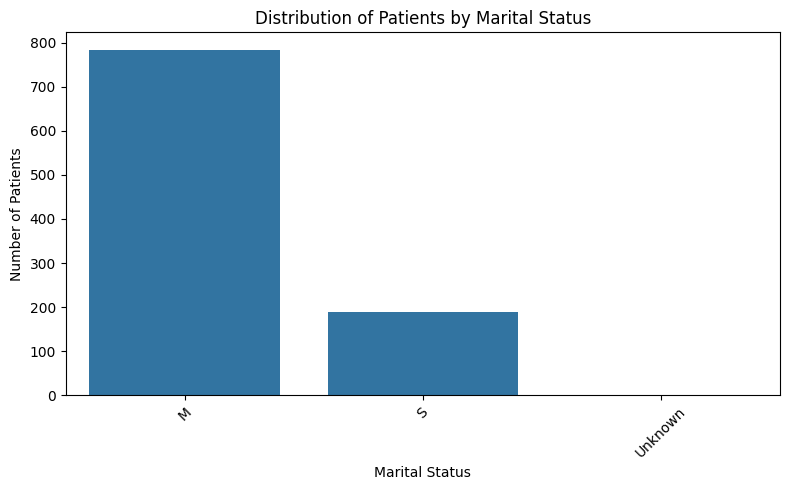

In [0]:
 # Count patients in each marital status category
marital_counts = patients["MARITAL"].fillna("Unknown").value_counts()

# Create bar chart
plt.figure(figsize=(8, 5))
sns.barplot(
    x=marital_counts.index,
    y=marital_counts.values
)

# Add chart labels
plt.title("Distribution of Patients by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

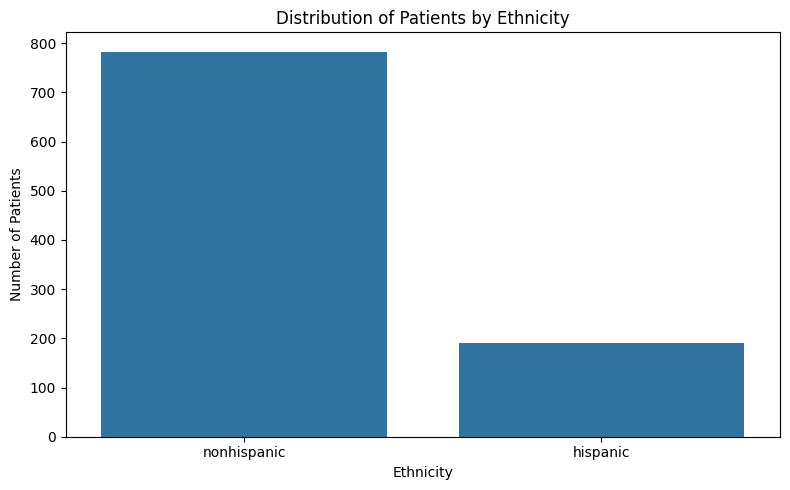

In [0]:
 
# Count patients by ethnicity
ethnicity_counts = patients["ETHNICITY"].value_counts()

# Create the bar chart
plt.figure(figsize=(8, 5))
sns.barplot(
    x=ethnicity_counts.index,
    y=ethnicity_counts.values
)

# Add labels and title
plt.title("Distribution of Patients by Ethnicity")
plt.xlabel("Ethnicity")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()


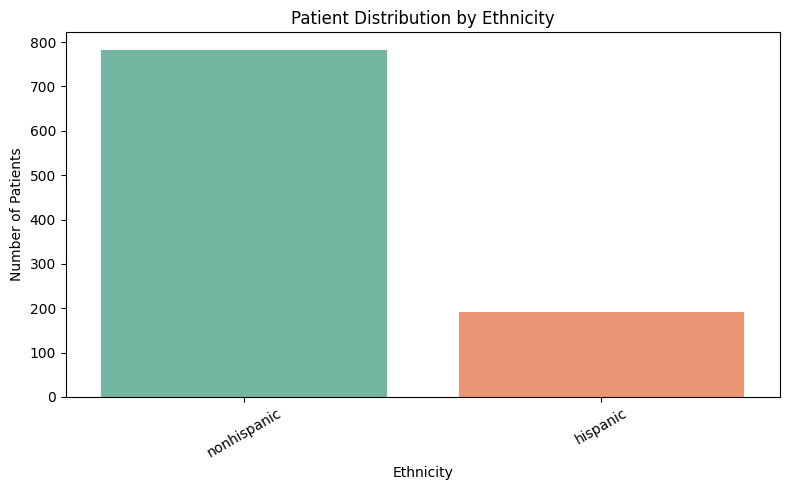

In [0]:
 
ethnicity_counts = patients["ETHNICITY"].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(
    x=ethnicity_counts.index,
    y=ethnicity_counts.values,
    hue=ethnicity_counts.index,
    palette="Set2",
    legend=False
)

plt.title("Patient Distribution by Ethnicity")
plt.xlabel("Ethnicity")
plt.ylabel("Number of Patients")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


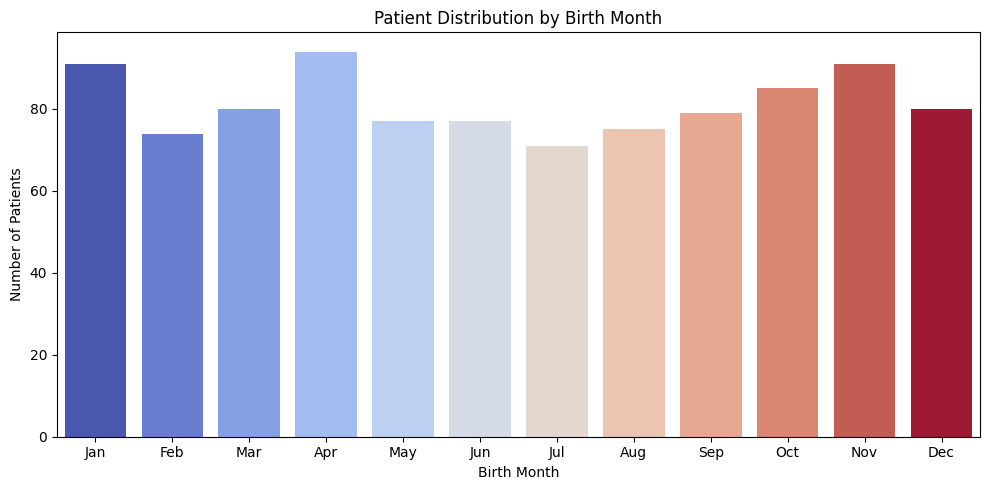

In [0]:
 
month_counts = patients["BIRTH_MONTH"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
sns.barplot(
    x=month_counts.index,
    y=month_counts.values,
    hue=month_counts.index,
    palette="coolwarm",
    legend=False
)

plt.title("Patient Distribution by Birth Month")
plt.xlabel("Birth Month")
plt.ylabel("Number of Patients")
plt.xticks(range(12), [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
])
plt.tight_layout()
plt.show()


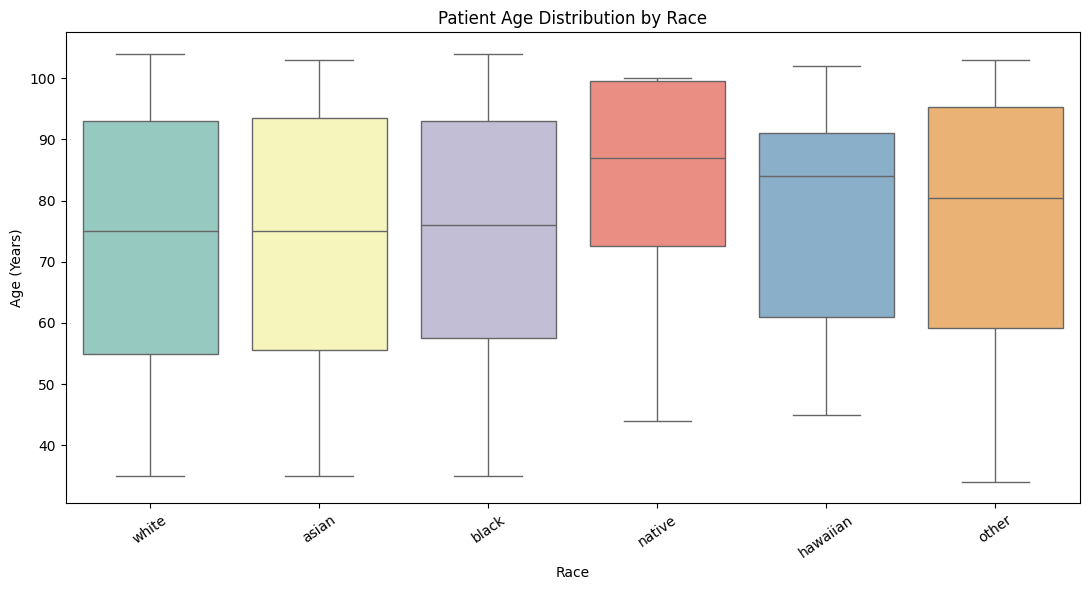

In [0]:
 
#Patient age distribution by race
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=patients,
    x="RACE",
    y="AGE",
    hue="RACE",
    palette="Set3",
    legend=False
)

plt.title("Patient Age Distribution by Race")
plt.xlabel("Race")
plt.ylabel("Age (Years)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()


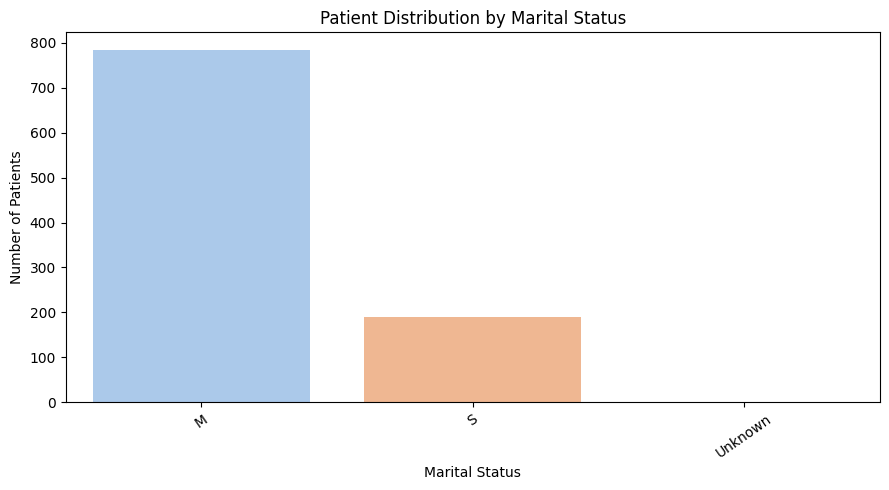

In [0]:
 
#Patient distribution by marital status 
marital_counts = patients["MARITAL"].fillna("Unknown").value_counts()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=marital_counts.index,
    y=marital_counts.values,
    hue=marital_counts.index,
    palette="pastel",
    legend=False
)

plt.title("Patient Distribution by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Number of Patients")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()


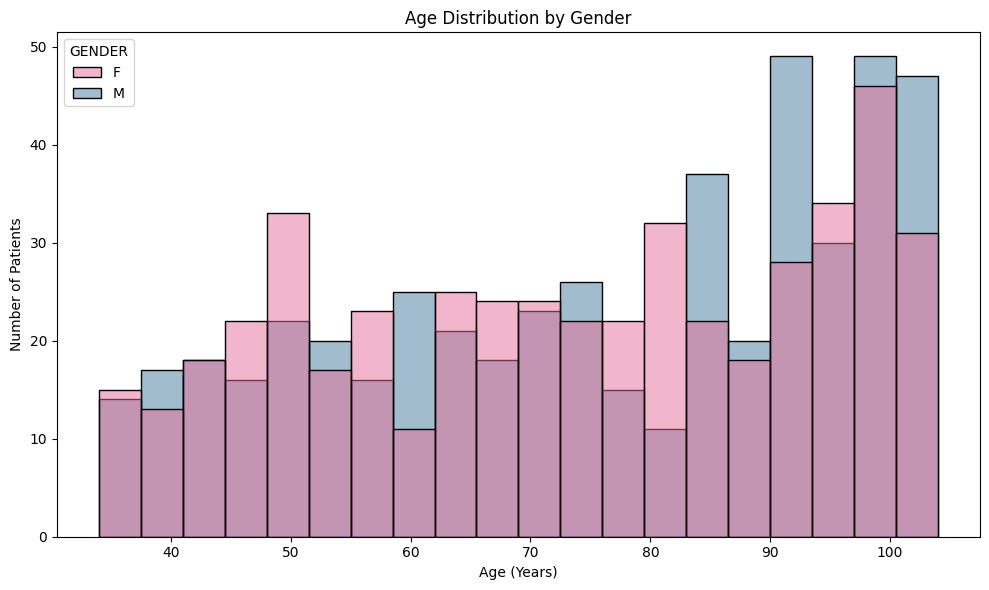

In [0]:
 
#Age distribution by gender
plt.figure(figsize=(10, 6))

sns.histplot(
    data=patients,
    x="AGE",
    hue="GENDER",
    bins=20,
    multiple="layer",
    palette={"F": "#E76F9A", "M": "#457B9D"},
    alpha=0.5
)

plt.title("Age Distribution by Gender")
plt.xlabel("Age (Years)")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()


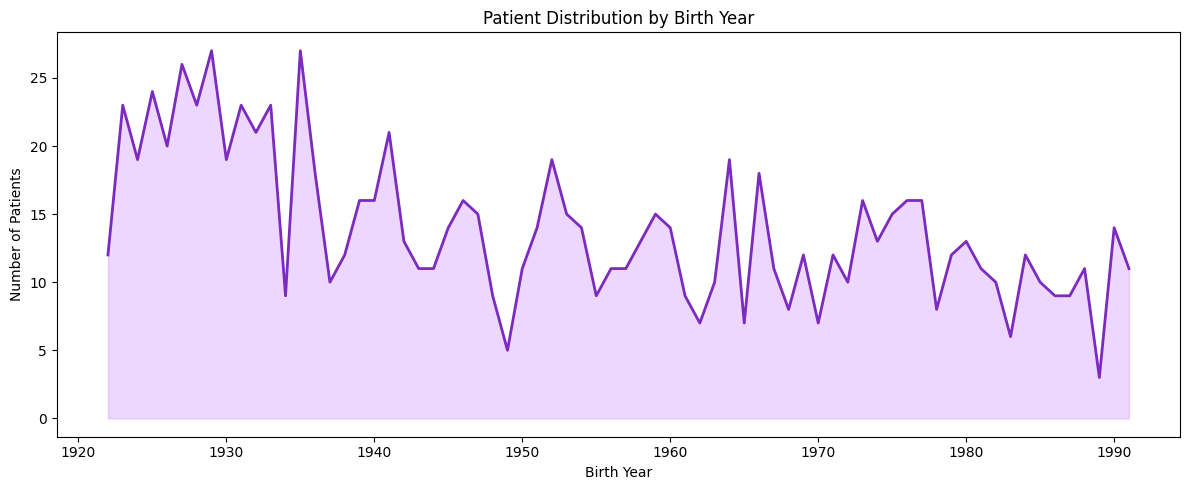

In [0]:
 
#Patient distribution by birth year
birth_year_counts = patients["BIRTH_YEAR"].value_counts().sort_index()

plt.figure(figsize=(12, 5))

plt.plot(
    birth_year_counts.index,
    birth_year_counts.values,
    color="#7B2CBF",
    linewidth=2
)

plt.fill_between(
    birth_year_counts.index,
    birth_year_counts.values,
    color="#C77DFF",
    alpha=0.3
)

plt.title("Patient Distribution by Birth Year")
plt.xlabel("Birth Year")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()




## 1. Research Question and Objectives

### 1.1 Research Question

How does the age distribution of patients differ across gender groups?

### 1.2 Relevance of the Research Question

Understanding the age distribution of patients across gender groups can provide useful demographic insights into the patient population. Age is an important demographic characteristic in healthcare because healthcare needs and patterns of service utilisation may vary across different age groups.

Comparing patient ages across gender groups can help identify demographic differences and provide a better understanding of the population represented in the dataset.

### 1.3 Research Objectives

The objectives of this investigation are:

1. To examine the age distribution of patients in the dataset.
2. To compare the average and median ages across gender groups.
3. To identify demographic patterns within the patient population.
4. To investigate whether patient age differs across gender groups.
5. To discuss the limitations of the available data and provide recommendations based on the findings.

## 2. Data Preparation Approach

### 2.1 Dataset Inspection

The Patients dataset was used for this investigation. It contained 974 records and 20 columns, providing demographic, birth, death and geographical information about patients.

The dataset was initially inspected to understand its structure, column names, data types and missing values.

### 2.2 Data Cleaning

The BIRTHDATE and DEATHDATE columns were converted into datetime format to support date-based analysis.

Missing values were investigated across the dataset. The MARITAL column contained one missing value, which was replaced with the category "Unknown". Other missing values, including those in DEATHDATE, SUFFIX, MAIDEN and ZIP, were retained because they represented unavailable information and did not all require replacement.

The dataset was also checked for duplicate records and duplicate patient identifiers. No duplicate rows or duplicate patient IDs were identified.

### 2.3 Data Transformation and Feature Engineering

The ZIP column was converted into a nullable string data type to preserve its role as an identifier rather than a numerical measurement.

Additional date components, including BIRTH_YEAR, BIRTH_MONTH and BIRTH_DAY, were extracted from the BIRTHDATE column.

A patient age variable was also calculated to support the investigation of age distributions and comparisons across gender groups.

### 2.4 Preparation for Analysis

After cleaning and transformation, the prepared dataset was used for demographic analysis. Patient age was examined using descriptive statistics, including the mean and median, and compared across gender groups.

These preparation steps helped improve data consistency and made the dataset suitable for the planned exploratory and statistical analysis.

## 3. Exploratory Findings

### 3.1 Patient Distribution by Gender

The Patients dataset contains 974 records. The gender distribution consists of 480 female patients and 494 male patients.

The male group represents a slightly larger proportion of the dataset than the female group. However, the difference in group sizes is relatively small.

### 3.2 Age Distribution Across Gender Groups

Descriptive statistics were used to compare patient ages across gender groups.

The female group had a mean age of approximately 73.00 years and a median age of 74 years. The male group had a mean age of approximately 75.26 years and a median age of 78 years.

These findings indicate that male patients were slightly older than female patients in the available dataset, based on both the mean and median ages.

### 3.3 Overall Exploratory Interpretation

The exploratory analysis identified a small difference in age distribution between the two gender groups. Male patients had higher average and median ages than female patients.

However, descriptive statistics alone cannot establish whether this difference is statistically significant. Further statistical analysis is required before drawing conclusions about the relationship between age and gender in the dataset.